# Reacher: Complete Chart-Count and Rank Ablation

All tested chart counts in one notebook:
**K = 1, 2, 4, 8, 16, 24, 32, 48, 64, 80, 96**, for **p=8 and p=10,
without and with graph guidance**, using **development seeds 211--310**.
These are not the 500-seed evaluation results on seeds 10001--10500.

The overview combines all 44 method/K best-rank results. The detailed sections
retain the full K=48/64/80/96 rank tables, serial metrics, and diagnostic plots.
For the 21 low-K completion searches, losing-rank checkpoints were intentionally
deleted after selection; only the selected ranks and success rates remain.
The original p=10 guided low-K study used a coarse search and local refinement.
Do not interpret all points as having identical rank-search budgets.

**Run All is report-only by default.** Optional low-K batch controls are at the
end, with RUN_BATCH=False. They retain the previous bounded/resumable runner.
The original result folders and experiment data remain separate and unchanged.

## Protocol and Interpretation

- Unstandardized linear charts, full-window projection-residual selection (L=12).
- Tracking + input effort + initial-output slack, lambda_ini=100000, Clarabel.
- Guided: chordal graph costs, waypoints, iterative N=10 terminal selection.
- Unguided: one fixed nearest eligible terminal configuration.
- Select highest success, then lowest median rollout RMSE, then lowest rank.
  Exception: the success-only low-K completion uses lowest rank to break ties.
- Strict success requires final-30 and final-100 mean errors below 10 mm and
  maximum errors below 20 mm. Failed solves remain in the statistics.
- Final-error quantiles summarize each rollout's final-100 mean error. Rollout
  RMSE includes the entire controlled trajectory, excluding warmup.
- Only selected-rank serial reruns are used for timing comparisons; sweep
  timings are affected by parallel execution. Separate sessions are not a
  controlled timing benchmark.
- Selection and reporting use the same exploratory seeds, not a held-out test.

The original p=10 guided chart-count study and K=48/64/80/96 rank sweeps were
measured at 320 controlled steps. The three-method low-K completion uses 300
steps. The overview's provenance table identifies the horizon of every point;
the merge does not relabel or recompute historical measurements.

The LTI dimension benchmark is $mL+n=2\times12+4=28$ for both output dimensions;
it is not a nonlinear rank guarantee. Ambient dimensions are 120 and 144.



In [1]:
import os
for variable in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[variable] = "1"
os.environ.setdefault("MPLCONFIGDIR", "/tmp/atlas_deepc_mpl")
from pathlib import Path
import json, sys
ROOT = next(root for parent in (Path.cwd(), *Path.cwd().parents)
            for root in (parent, parent / "code") if (root / "src/atlas_deepc").is_dir())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from atlas_deepc.reporting.rank_sweep_k48_k64 import load_saved, load_chart_counts, SOURCES
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
RUN_BATCH = False  # Explicit opt-in only, in the optional batch section below.
panels, provenance = load_saved()
count_points, count_provenance = load_chart_counts(panels)
ALL_COUNTS = (1, 2, 4, 8, 16, 24, 32, 48, 64, 80, 96)
COUNTS = (48, 64, 80, 96)
CASES = ((8, "terminal"), (8, "graph"), (10, "terminal"), (10, "graph"))
LABELS = ("p=8, no guidance", "p=8, guided", "p=10, no guidance", "p=10, guided")
records = [dict(row, K=k) for (k, p, mode), (curve, winner) in panels.items() for row in curve]
frame = pd.DataFrame(records)
selected = pd.DataFrame([
    dict(row, K=k) for k in COUNTS
    for row in json.loads((SOURCES[k] / "best_rank_table.json").read_text())["columns"]
])
assert len(frame) == 688 and len(selected) == 16
count_frame = pd.DataFrame(count_points).rename(columns={"charts": "K"})
assert not count_frame.duplicated(["K", "output_dimension", "reference_mode"]).any()
print("Verified: 4 chart counts, 688 complete rank/method panels, 68,800 sweep seed evaluations.")
print(f"Combined chart-count coverage: {len(count_frame)}/44 selected configurations.")


Verified K=48: 172 rank/configuration panels, 17,200 seed outcomes.


Verified K=64: 172 rank/configuration panels, 17,200 seed outcomes.


Verified K=80: 172 rank/configuration panels, 17,200 seed outcomes.


Verified K=96: 172 rank/configuration panels, 17,200 seed outcomes.


Verified chart-count curves: [(10, 'graph', 1, 53, 4), (10, 'graph', 2, 64, 9), (10, 'graph', 4, 58, 19), (10, 'graph', 8, 54, 47), (10, 'graph', 16, 54, 83), (10, 'graph', 24, 55, 90), (10, 'graph', 32, 60, 90), (10, 'graph', 48, 60, 93), (10, 'graph', 64, 62, 96.0), (10, 'graph', 80, 48, 93.0), (10, 'graph', 96, 45, 96.0), (8, 'terminal', 48, 53, 88.0), (8, 'terminal', 64, 53, 90.0), (8, 'terminal', 80, 49, 90.0), (8, 'terminal', 96, 57, 89.0), (8, 'graph', 48, 53, 89.0), (8, 'graph', 64, 54, 92.0), (8, 'graph', 80, 49, 92.0), (8, 'graph', 96, 57, 95.0), (10, 'terminal', 48, 57, 82.0), (10, 'terminal', 64, 65, 81.0), (10, 'terminal', 80, 64, 87.0), (10, 'terminal', 96, 54, 85.0), (8, 'terminal', 1, 69, 3.0), (8, 'graph', 1, 69, 3.0), (10, 'terminal', 1, 54, 4.0), (8, 'terminal', 2, 55, 5.0), (8, 'graph', 2, 55, 5.0), (10, 'terminal', 2, 46, 5.0), (8, 'terminal', 4, 58, 17.0), (8, 'graph', 4, 55, 22.0), (10, 'terminal', 4, 58, 19.0), (8, 'terminal', 8, 62, 37.0), (8, 'graph', 8, 59, 3

Verified: 4 chart counts, 688 complete rank/method panels, 68,800 sweep seed evaluations.
Combined chart-count coverage: 44/44 selected configurations.


## All Chart Counts: Best-Rank Success
Each cell shows success rate and selected rank. Missing entries remain blank; incomplete searches are not treated as winners.

In [2]:
def show_count_table(points):
    values = points.copy()
    values["result"] = values.apply(lambda r: f"{r.success_rate:.0f}% (rank {int(r['rank'])})", axis=1)
    table = values.pivot(index="K", columns=["output_dimension", "reference_mode"], values="result")
    table = table.reindex(index=ALL_COUNTS, columns=pd.MultiIndex.from_tuples(CASES))
    table.columns = LABELS
    display(table.fillna("Not complete"))

show_count_table(count_frame)


,"p=8, no guidance","p=8, guided","p=10, no guidance","p=10, guided"
K,,,,
1,3% (rank 69),3% (rank 69),4% (rank 54),4% (rank 53)
2,5% (rank 55),5% (rank 55),5% (rank 46),9% (rank 64)
4,17% (rank 58),22% (rank 55),19% (rank 58),19% (rank 58)
8,37% (rank 62),39% (rank 59),33% (rank 67),47% (rank 54)
16,56% (rank 59),80% (rank 51),48% (rank 57),83% (rank 54)
24,73% (rank 52),80% (rank 49),66% (rank 54),90% (rank 55)
32,73% (rank 48),89% (rank 57),69% (rank 69),90% (rank 60)
48,88% (rank 53),89% (rank 53),82% (rank 57),93% (rank 60)
64,90% (rank 53),92% (rank 54),81% (rank 65),96% (rank 62)


## Success Versus Number of Charts
Best among the tested ranks, on development seeds. The combined curve includes different saved horizons and tie-break rules, listed below.

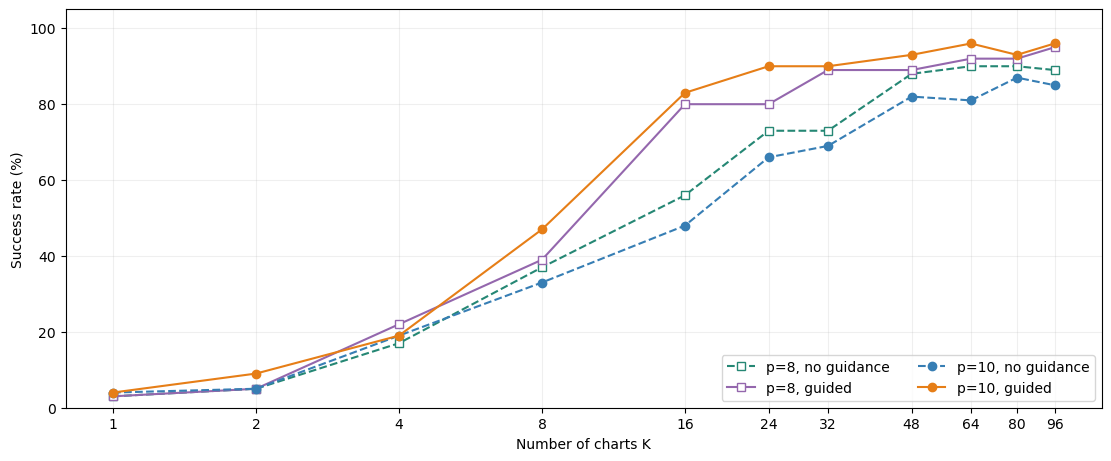

In [3]:
fig, ax = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
styles = (("#258774", "--", "s"), ("#9467ad", "-", "s"),
          ("#377eb4", "--", "o"), ("#e67e17", "-", "o"))
for (p, mode), label, (color, linestyle, marker) in zip(CASES, LABELS, styles):
    points = count_frame[(count_frame.output_dimension == p) & (count_frame.reference_mode == mode)].set_index("K").reindex(ALL_COUNTS)
    ax.plot(ALL_COUNTS, points.success_rate, linestyle=linestyle, marker=marker,
            color=color, label=label, markerfacecolor="white" if p == 8 else color)
ax.set(xscale="log", xlabel="Number of charts K", ylabel="Success rate (%)", ylim=(0, 105))
ax.set_xticks(ALL_COUNTS, labels=ALL_COUNTS)
ax.minorticks_off()
ax.grid(alpha=.2)
ax.legend(loc="lower right", ncol=2)
plt.show()


## Search Coverage and Provenance
Low-K completion retains only winners, not full rank curves. Original saved horizons are shown explicitly.

In [4]:
coverage = count_frame[["K", "output_dimension", "reference_mode", "rank", "success_rate", "controlled_steps", "tested_ranks"]].copy()
coverage["tested_rank_count"] = coverage.tested_ranks.map(len)
coverage["tie_break"] = coverage.controlled_steps.map({300: "lowest rank", 320: "lowest median RMSE, then rank"})
display(coverage.sort_values(["K", "output_dimension", "reference_mode"]).reset_index(drop=True))
print("Original guided chart-count source:", count_provenance["source"])
if "completion" in count_provenance:
    print("Low-K completion source:", count_provenance["completion"]["source"])


,K,output_dimension,reference_mode,rank,success_rate,controlled_steps,tested_ranks,tested_rank_count,tie_break
0,1,8,graph,69,3.0,300,"[28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 3...",43,lowest rank
1,1,8,terminal,69,3.0,300,"[28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 3...",43,lowest rank
2,1,10,graph,53,4.0,320,"[48, 52, 53, 54, 55, 56, 60, 66, 72]",9,"lowest median RMSE, then rank"
3,1,10,terminal,54,4.0,300,"[28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 3...",43,lowest rank
4,2,8,graph,55,5.0,300,"[28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 3...",43,lowest rank
5,2,8,terminal,55,5.0,300,"[28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 3...",43,lowest rank
6,2,10,graph,64,9.0,320,"[48, 54, 60, 64, 65, 66, 67, 68, 72]",9,"lowest median RMSE, then rank"
7,2,10,terminal,46,5.0,300,"[28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 3...",43,lowest rank
8,4,8,graph,55,22.0,300,"[28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 3...",43,lowest rank
9,4,8,terminal,58,17.0,300,"[28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 3...",43,lowest rank


Original guided chart-count source: experiments/reacher/chart_count_rank_projection_chordal_v1
Low-K completion source: experiments/reacher/low_k_missing_batches_t300_v3/summary.json


## Selected Ranks: K = 48, 64, 80, 96
Serially verified best configurations for each K and method.

In [5]:
display(selected[["K", "output_dimension", "reference_mode", "rank", "success_rate",
                  "median_error_mm", "median_rollout_rmse_mm", "median_time_ms"]].round(3))


,K,output_dimension,reference_mode,rank,success_rate,median_error_mm,median_rollout_rmse_mm,median_time_ms
0,48,8,terminal,53,88.0,1.993,61.217,27.890
1,48,8,graph,53,89.0,2.281,61.105,27.845
2,48,10,terminal,57,82.0,2.011,58.146,30.179
3,48,10,graph,60,93.0,2.094,65.372,30.383
4,64,8,terminal,53,90.0,1.781,59.721,19.729
5,64,8,graph,54,92.0,2.076,72.983,19.660
6,64,10,terminal,65,81.0,1.883,65.688,23.340
7,64,10,graph,62,96.0,2.194,64.109,22.098
8,80,8,terminal,49,90.0,2.175,60.137,19.050
9,80,8,graph,49,92.0,2.177,63.278,19.112


## Success Versus Rank
Outlined markers identify the selected ranks; tied maximum success rates use the RMSE tie-breaker.

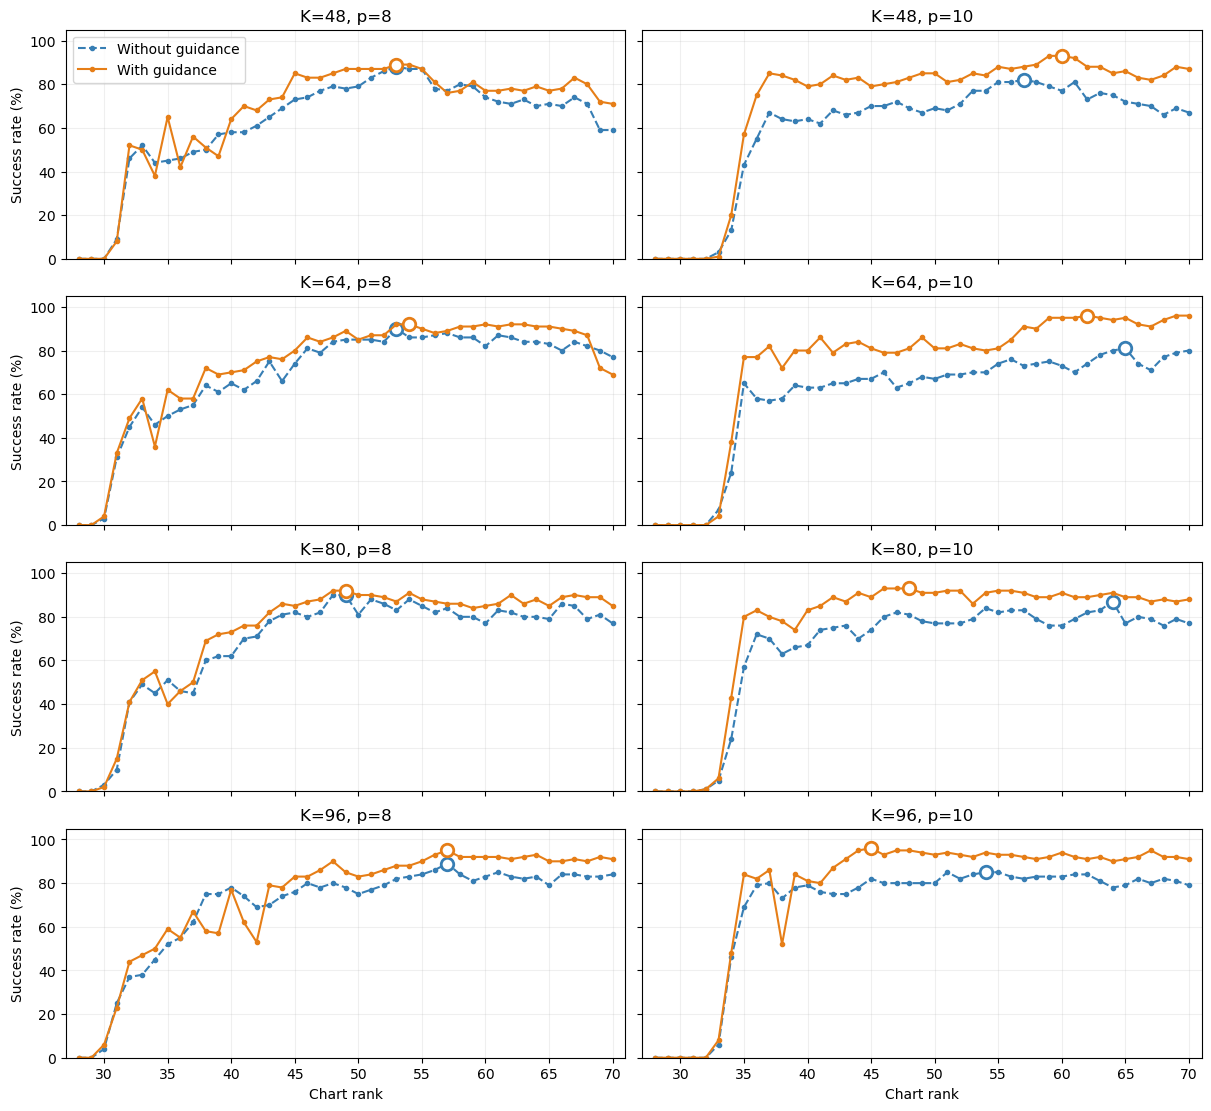

In [6]:
fig, axes = plt.subplots(4, 2, figsize=(12, 11), sharex=True, sharey=True, constrained_layout=True)
for row, k in enumerate(COUNTS):
    for col, p in enumerate((8, 10)):
        ax = axes[row, col]
        for mode, label, color, style in (("terminal", "Without guidance", "#377eb4", "--"),
                                           ("graph", "With guidance", "#e67e17", "-")):
            curve, winner = panels[k, p, mode]
            data = pd.DataFrame(curve)
            ax.plot(data["rank"], data.success_rate, marker=".", linestyle=style, color=color, label=label)
            ax.plot(winner["rank"], winner["success_rate"], "o", color=color,
                    markerfacecolor="white", markersize=9, markeredgewidth=2)
        ax.set(title=f"K={k}, p={p}", ylim=(0, 105), xlim=(27, 71))
        ax.grid(alpha=.2)
        if col == 0: ax.set_ylabel("Success rate (%)")
        if row == 3: ax.set_xlabel("Chart rank")
axes[0, 0].legend()
plt.show()


## K = 48
Complete success-rate table, selected-rank serial metrics, and tracking diagnostics.

,"p=8, no guidance","p=8, guided","p=10, no guidance","p=10, guided"
rank,,,,
28,0%,0%,0%,0%
29,0%,0%,0%,0%
30,0%,0%,0%,0%
31,9%,8%,0%,0%
32,46%,52%,0%,0%
33,52%,50%,3%,1%
34,44%,38%,13%,20%
35,45%,65%,43%,57%
36,46%,42%,55%,75%


,"p=8, no guidance","p=8, guided","p=10, no guidance","p=10, guided"
rank,53.000,53.000,57.000,60.000
success_rate,88.000,89.000,82.000,93.000
median_error_mm,1.993,2.281,2.011,2.094
p90_error_mm,28.565,16.393,235.958,5.251
p95_error_mm,49.279,30.175,317.468,15.345
p99_error_mm,212.037,48.130,362.379,45.576
median_rollout_rmse_mm,61.217,61.105,58.146,65.372
median_time_ms,27.890,27.845,30.179,30.383
p95_time_ms,37.161,42.926,45.560,45.817
p99_time_ms,58.422,60.011,64.215,63.885


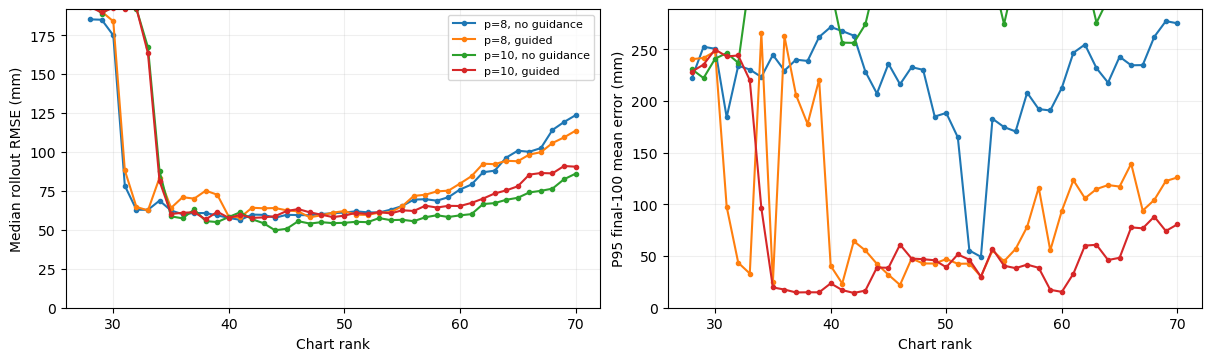

rank,output_dimension,reference_mode,graph_guidance,seeds,successes,success_rate,median_error_mm,p90_error_mm,p95_error_mm,p99_error_mm,median_rollout_rmse_mm,pooled_rmse_mm,unsolved_steps,failed_seeds,median_time_ms,p95_time_ms,p99_time_ms,timing_workers,summary_sha256,source_directory,rank60_reused,inaccurate_steps,K,solver_status_counts,clusters,serial
28,8,terminal,False,100,0,0.0,172.514,218.511,222.454,246.682,185.325,189.652,0,"[211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310]",30.636,54.716,77.200,4,7899a9adc1b0ec0491be0e00dce683f4cfeeeab033b6d83c1df78e0646ea8dc9,/Users/kumiko/Projects/atlas_deepc_reacher/experiments/reacher/projection_chordal_rank_lamg0_lamdu0_clarabel_v1/rank028/output8/terminal,False,1.0,48,NaN,NaN,NaN
29,8,terminal,False,100,0,0.0,163.506,223.825,252.565,270.188,185.080,187.651,0,"[211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310]",31.860,56.485,80.441,4,9b1447aa542acc9011dee5e04683a6d2570900356c469152aaac9ac5e3e16e7a,/Users/kumiko/Projects/atlas_deepc_reacher/experiments/reacher/projection_chordal_rank_lamg0_lamdu0_clarabel_v1/rank029/output8/terminal,False,0.0,48,NaN,NaN,NaN
30,8,terminal,False,100,0,0.0,158.380,232.619,250.616,304.219,175.055,184.845,0,"[211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310]",31.269,53.778,75.445,4,c5eb3b3996cf95be01a3aebcba0eb0c5e30d6e1cca768bfca4b209900242ec58,/Users/kumiko/Projects/atlas_deepc_reacher/experiments/reacher/projection_chordal_rank_lamg0_lamdu0_clarabel_v1/rank030/output8/terminal,False,0.0,48,NaN,NaN,NaN
31,8,terminal,False,100,9,9.0,38.970,94.971,184.341,276.895,78.341,107.184,0,"[211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 223, 224, 225, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 268, 269, 270, 272, 273, 274, 275, 276, 277, 279, 280, 282, 283, 284, 285, 286, 287, 288, 289, 291, 292, 293, 294, 295, 296, 297, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310]",30.214,50.500,70.642,4,506f8aa5e8cbb69ca8cbe6b60016de4b33aefd46efa509d7e3a5779a3c1b0423,/Users/kumiko/Projects/atlas_deepc_reacher/experiments/reacher/projection_chordal_rank_lamg0_lamdu0_clarabel_v1/rank031/output8/terminal,False,0.0,48,NaN,NaN,NaN
32,8,terminal,False,100,46,46.0,10.100,188.806,234.208,271.332,62.992,108.334,0,"[212, 214, 215, 216, 217, 218, 220, 221, 223, 225, 230, 231, 232, 233, 237, 240, 243, 244, 245, 247, 249, 252, 255, 258, 259, 260, 261, 262, 267, 270, 274, 275, 277, 281, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 294, 296, 297, 298, 299, 303, 304, 305, 306, 307]",29.77

rank  \
output_dimension reference_mode         
8                terminal          53   
                 graph             53   
10               terminal          57   
                 graph             60   

                                                                      failed_seeds  
output_dimension reference_mode                                                     
8                terminal        [222, 229, 231, 245, 252, 262, 283, 284, 287, ...  
                 graph           [222, 231, 236, 245, 252, 262, 281, 284, 287, ...  
10               terminal        [233, 236, 237, 245, 250, 252, 254, 262, 269, ...  
                 graph                         [222, 236, 245, 252, 254, 277, 284]

\begin{table}[htbp]
    \centering
    \small
    \begin{tabular}{lrrrr}
        \toprule
        Output dimension & \multicolumn{2}{c}{$p=8$} & \multicolumn{2}{c}{$p=10$} \\
        \cmidrule(lr){2-3}\cmidrule(lr){4-5}
        Graph guidance & No & Yes & No & Yes \\
        \midrule
        Selected rank & 53 & 53 & 57 & 60 \\
        Success rate $\uparrow$ & 88\% & 89\% & 82\% & \textbf{93\%} \\
        Median error (mm) $\downarrow$ & \textbf{1.99} & 2.28 & 2.01 & 2.09 \\
        90th-percentile error (mm) $\downarrow$ & 28.565 & 16.393 & 235.958 & \textbf{5.251} \\
        95th-percentile error (mm) $\downarrow$ & 49.279 & 30.175 & 317.468 & \textbf{15.345} \\
        99th-percentile error (mm) $\downarrow$ & 212.037 & 48.130 & 362.379 & \textbf{45.576} \\
        Median rollout RMSE (mm) $\downarrow$ & 61.22 & 61.11 & \textbf{58.15} & 65.37 \\
        \midrule
        \multicolumn{5}{l}{\textit{Total online computation time (ms)}} \\
        Median & 27.89 & 27.85 & 30.18 & 30.38

In [7]:
k = 48
data = frame[frame.K == k].copy()
rates = data.pivot(index="rank", columns=["output_dimension", "reference_mode"], values="success_rate")
rates = rates.reindex(columns=pd.MultiIndex.from_tuples(CASES))
rates.columns = LABELS
display(rates.style.format("{:.0f}%"))
best = selected[selected.K == k].set_index(["output_dimension", "reference_mode"]).reindex(CASES)
metrics = ["rank", "success_rate", "median_error_mm", "p90_error_mm", "p95_error_mm", "p99_error_mm",
           "median_rollout_rmse_mm", "median_time_ms", "p95_time_ms", "p99_time_ms"]
table = best[metrics].T
table.columns = LABELS
display(table.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), constrained_layout=True)
for (p, mode), label in zip(CASES, LABELS):
    curve = data[(data.output_dimension == p) & (data.reference_mode == mode)].sort_values("rank")
    for ax, metric, ylabel in ((axes[0], "median_rollout_rmse_mm", "Median rollout RMSE (mm)"),
                               (axes[1], "p95_error_mm", "P95 final-100 mean error (mm)")):
        ax.plot(curve["rank"], curve[metric], ".-", label=label)
        ax.set(xlabel="Chart rank", ylabel=ylabel, ylim=(0, None))
        ax.grid(alpha=.2)
axes[0].legend(fontsize=8)
plt.show()
details = data.drop(columns=["timing_modules", "per_seed_rmse_mm"], errors="ignore")
display(HTML("<details><summary>All saved rank metrics and solver diagnostics</summary>" +
             details.round(3).to_html(index=False) + "</details>"))
if "failed_seeds" in best:
    display(best[["rank", "failed_seeds"]])
latex = SOURCES[k] / "table_best_ranks.tex"
if latex.exists():
    print(latex.read_text())


## K = 64
Complete success-rate table, selected-rank serial metrics, and tracking diagnostics.

,"p=8, no guidance","p=8, guided","p=10, no guidance","p=10, guided"
rank,,,,
28,0%,0%,0%,0%
29,0%,0%,0%,0%
30,3%,4%,0%,0%
31,31%,33%,0%,0%
32,45%,49%,0%,0%
33,54%,58%,7%,4%
34,46%,36%,24%,38%
35,50%,62%,65%,77%
36,53%,58%,58%,77%


,"p=8, no guidance","p=8, guided","p=10, no guidance","p=10, guided"
rank,53.000,54.000,65.000,62.000
success_rate,90.000,92.000,81.000,96.000
median_error_mm,1.781,2.076,1.883,2.194
p90_error_mm,10.066,6.578,255.670,4.445
p95_error_mm,151.325,17.793,308.355,5.248
p99_error_mm,244.993,72.195,339.561,48.879
median_rollout_rmse_mm,59.721,72.983,65.688,64.109
median_time_ms,19.729,19.660,23.340,22.098
p95_time_ms,22.194,22.399,27.152,25.161
p99_time_ms,58.192,57.246,60.337,58.669


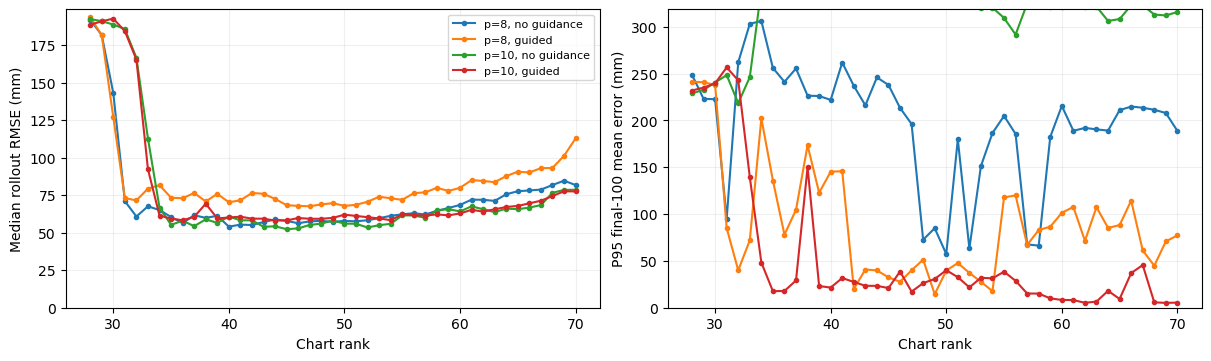

rank,output_dimension,reference_mode,graph_guidance,seeds,successes,success_rate,median_error_mm,p90_error_mm,p95_error_mm,p99_error_mm,median_rollout_rmse_mm,pooled_rmse_mm,unsolved_steps,failed_seeds,median_time_ms,p95_time_ms,p99_time_ms,timing_workers,summary_sha256,source_directory,rank60_reused,inaccurate_steps,K,solver_status_counts,clusters,serial
28,8,terminal,False,100,0,0.0,173.970,231.358,248.875,284.358,192.025,191.708,0,"[211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310]",19.386,25.815,50.318,4,4264c43e507e7ba127ee2dd406d62be10f46a2d59429abf6b540f70134933200,/Users/kumiko/Projects/atlas_deepc_reacher/experiments/reacher/four_baselines_k64_rank_projection_chordal_v1/sweep/rank028/output8/terminal,False,NaN,64,"{'optimal': 31999, 'optimal_inaccurate': 1}",64.0,False
29,8,terminal,False,100,0,0.0,164.292,213.993,223.136,251.516,181.774,179.850,1,"[211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310]",19.399,26.706,52.196,4,98e13fc9b0a23c9de2d82c52d3a529864231dd8311d4e63c6e01823651770262,/Users/kumiko/Projects/atlas_deepc_reacher/experiments/reacher/four_baselines_k64_rank_projection_chordal_v1/sweep/rank029/output8/terminal,False,NaN,64,"{'optimal': 31999, 'user_limit': 1}",64.0,False
30,8,terminal,False,100,3,3.0,100.580,206.269,222.733,242.195,143.132,147.860,0,"[211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 291, 292, 293, 294, 295, 296, 297, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310]",19.490,27.781,52.665,4,76a084b4d75003c332527d4ea92d10eaec899cd53e3d84326cb4d3a2c8c084b1,/Users/kumiko/Projects/atlas_deepc_reacher/experiments/reacher/four_baselines_k64_rank_projection_chordal_v1/sweep/rank030/output8/terminal,False,NaN,64,{'optimal': 32000},64.0,False
31,8,terminal,False,100,31,31.0,16.660,78.221,94.757,214.484,71.067,90.230,0,"[212, 214, 215, 216, 217, 218, 220, 221, 223, 225, 226, 227, 228, 230, 233, 234, 235, 236, 238, 240, 241, 243, 244, 245, 246, 248, 249, 251, 252, 254, 255, 256, 257, 258, 259, 260, 263, 264, 265, 266, 268, 269, 270, 271, 272, 273, 274, 275, 276, 278, 279, 280, 282, 285, 286, 287, 288, 291, 292, 293, 296, 299, 300, 301, 302, 305, 306, 307, 308]",18.855,25.067,50.169,4,7818df10b3977210201eefeb6e812a845ed497eb485481d5c21fd314f02edb46,/Users/kumiko/Projects/atlas_deepc_reacher/experiments/reacher/four_baselines_k64_rank_projection_chordal_v1/sweep/rank031/output8/terminal,False,NaN,64,{'optimal': 32000},64.0,False
32,8,terminal,False,100,45,45.0,10.457,55.666,262.145,332.546,60.807,102.183,1,"[214, 215, 216, 217, 218, 219, 220, 223, 225, 226, 227, 232, 233, 235, 237, 239, 240, 245, 246, 248, 249, 252, 254, 255, 256, 257, 258, 260, 263, 265, 269, 271, 272, 274, 275, 276, 279, 282, 285, 287, 288, 291, 292, 296, 299, 300, 301, 302, 303, 304, 305, 306, 307, 309, 31

rank  \
output_dimension reference_mode         
8                terminal          53   
                 graph             54   
10               terminal          65   
                 graph             62   

                                                                      failed_seeds  
output_dimension reference_mode                                                     
8                terminal        [222, 236, 245, 252, 254, 278, 281, 290, 296, ...  
                 graph                    [236, 245, 252, 254, 277, 287, 290, 296]  
10               terminal        [222, 232, 236, 237, 241, 245, 250, 252, 262, ...  
                 graph                                        [222, 245, 290, 298]

\begin{table}[htbp]
    \centering
    \small
    \begin{tabular}{lrrrr}
        \toprule
        Output dimension & \multicolumn{2}{c}{$p=8$} & \multicolumn{2}{c}{$p=10$} \\
        \cmidrule(lr){2-3}\cmidrule(lr){4-5}
        Graph guidance & No & Yes & No & Yes \\
        \midrule
        Selected rank & 53 & 54 & 65 & 62 \\
        Success rate $\uparrow$ & 90\% & 92\% & 81\% & \textbf{96\%} \\
        Median error (mm) $\downarrow$ & \textbf{1.78} & 2.08 & 1.88 & 2.19 \\
        90th-percentile error (mm) $\downarrow$ & 10.066 & 6.578 & 255.670 & \textbf{4.445} \\
        95th-percentile error (mm) $\downarrow$ & 151.325 & 17.793 & 308.355 & \textbf{5.248} \\
        99th-percentile error (mm) $\downarrow$ & 244.993 & 72.195 & 339.561 & \textbf{48.879} \\
        Median rollout RMSE (mm) $\downarrow$ & \textbf{59.72} & 72.98 & 65.69 & 64.11 \\
        \midrule
        \multicolumn{5}{l}{\textit{Total online computation time (ms)}} \\
        Median & 19.73 & 19.66 & 23.34 & 22.10 

In [8]:
k = 64
data = frame[frame.K == k].copy()
rates = data.pivot(index="rank", columns=["output_dimension", "reference_mode"], values="success_rate")
rates = rates.reindex(columns=pd.MultiIndex.from_tuples(CASES))
rates.columns = LABELS
display(rates.style.format("{:.0f}%"))
best = selected[selected.K == k].set_index(["output_dimension", "reference_mode"]).reindex(CASES)
metrics = ["rank", "success_rate", "median_error_mm", "p90_error_mm", "p95_error_mm", "p99_error_mm",
           "median_rollout_rmse_mm", "median_time_ms", "p95_time_ms", "p99_time_ms"]
table = best[metrics].T
table.columns = LABELS
display(table.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), constrained_layout=True)
for (p, mode), label in zip(CASES, LABELS):
    curve = data[(data.output_dimension == p) & (data.reference_mode == mode)].sort_values("rank")
    for ax, metric, ylabel in ((axes[0], "median_rollout_rmse_mm", "Median rollout RMSE (mm)"),
                               (axes[1], "p95_error_mm", "P95 final-100 mean error (mm)")):
        ax.plot(curve["rank"], curve[metric], ".-", label=label)
        ax.set(xlabel="Chart rank", ylabel=ylabel, ylim=(0, None))
        ax.grid(alpha=.2)
axes[0].legend(fontsize=8)
plt.show()
details = data.drop(columns=["timing_modules", "per_seed_rmse_mm"], errors="ignore")
display(HTML("<details><summary>All saved rank metrics and solver diagnostics</summary>" +
             details.round(3).to_html(index=False) + "</details>"))
if "failed_seeds" in best:
    display(best[["rank", "failed_seeds"]])
latex = SOURCES[k] / "table_best_ranks.tex"
if latex.exists():
    print(latex.read_text())


## K = 80
Complete success-rate table, selected-rank serial metrics, and tracking diagnostics.

,"p=8, no guidance","p=8, guided","p=10, no guidance","p=10, guided"
rank,,,,
28,0%,0%,0%,0%
29,0%,0%,0%,0%
30,3%,2%,0%,0%
31,10%,15%,0%,0%
32,41%,41%,1%,1%
33,49%,51%,5%,6%
34,45%,55%,24%,43%
35,51%,40%,57%,80%
36,46%,46%,72%,83%


,"p=8, no guidance","p=8, guided","p=10, no guidance","p=10, guided"
rank,49.000,49.000,64.000,48.000
success_rate,90.000,92.000,87.000,93.000
median_error_mm,2.175,2.177,1.587,3.558
p90_error_mm,9.714,6.912,42.074,8.957
p95_error_mm,88.563,51.647,259.420,14.934
p99_error_mm,275.767,88.736,317.826,23.868
median_rollout_rmse_mm,60.137,63.278,62.519,61.039
median_time_ms,19.050,19.112,22.835,19.952
p95_time_ms,27.715,28.242,29.482,28.159
p99_time_ms,50.954,50.710,50.924,50.728


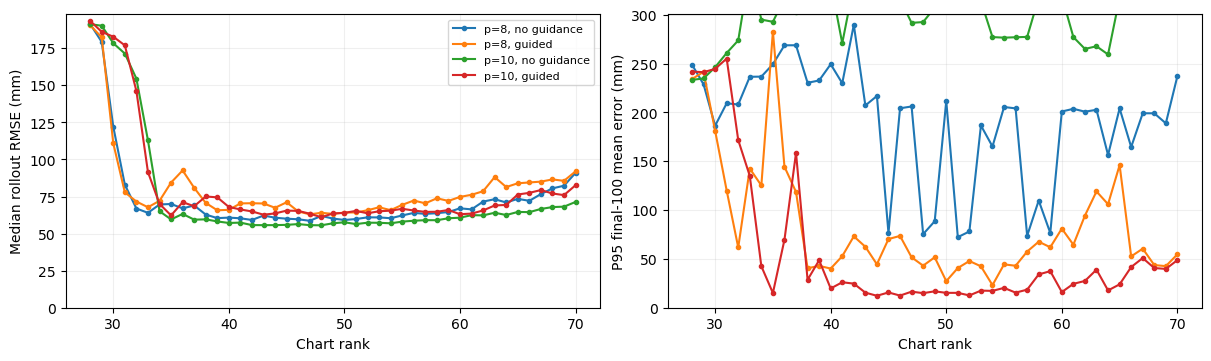

rank,output_dimension,reference_mode,graph_guidance,seeds,successes,success_rate,median_error_mm,p90_error_mm,p95_error_mm,p99_error_mm,median_rollout_rmse_mm,pooled_rmse_mm,unsolved_steps,failed_seeds,median_time_ms,p95_time_ms,p99_time_ms,timing_workers,summary_sha256,source_directory,rank60_reused,inaccurate_steps,K,solver_status_counts,clusters,serial
28,8,terminal,False,100,0,0.0,172.891,238.395,248.994,265.295,191.339,190.311,0,"[211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310]",19.452,30.563,54.843,4,931ef3c641c2e0686f67094623dd46fb8e904ceb6f06192749abbaf4f29e58e3,/Users/kumiko/Projects/atlas_deepc_reacher/experiments/reacher/large_k_rank_compact_v1/k080/sweep/rank028/output8/terminal,False,NaN,80,{'optimal': 32000},80.0,False
29,8,terminal,False,100,0,0.0,153.570,210.463,228.819,265.917,179.242,178.612,0,"[211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310]",19.388,35.707,67.936,4,c98b0724c752bd0d025b5c8fa420b5cdb18efe0109d134299d765b9f6a22a67b,/Users/kumiko/Projects/atlas_deepc_reacher/experiments/reacher/large_k_rank_compact_v1/k080/sweep/rank029/output8/terminal,False,NaN,80,{'optimal': 32000},80.0,False
30,8,terminal,False,100,3,3.0,85.169,180.145,186.416,203.239,122.071,128.535,0,"[211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 252, 253, 254, 255, 256, 257, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310]",19.038,31.350,59.569,4,049489530970282c9313dad92e30433de73ea924aa98f852883323304d528cb4,/Users/kumiko/Projects/atlas_deepc_reacher/experiments/reacher/large_k_rank_compact_v1/k080/sweep/rank030/output8/terminal,False,NaN,80,{'optimal': 32000},80.0,False
31,8,terminal,False,100,10,10.0,32.560,124.398,209.399,276.933,82.956,110.083,0,"[211, 212, 213, 214, 215, 216, 217, 218, 219, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 244, 245, 246, 247, 249, 250, 251, 252, 253, 254, 255, 256, 257, 260, 261, 262, 263, 264, 265, 267, 268, 269, 270, 271, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 287, 288, 289, 290, 291, 292, 293, 294, 296, 297, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310]",18.997,32.045,59.761,4,6b7eb4ff9888ad2abcf77942ef673f144cddcbccb328be3db8e2162cf1734e43,/Users/kumiko/Projects/atlas_deepc_reacher/experiments/reacher/large_k_rank_compact_v1/k080/sweep/rank031/output8/terminal,False,NaN,80,{'optimal': 32000},80.0,False
32,8,terminal,False,100,41,41.0,12.296,45.263,208.167,276.895,66.918,90.904,0,"[211, 212, 213, 214, 216, 218, 219, 226, 227, 230, 231, 232, 234, 236, 237, 238, 239, 245, 247, 248, 250, 252, 254, 255, 257, 258, 261, 262, 265, 267, 268, 270, 271, 273, 274, 275, 279, 280, 282, 284, 285, 288, 289, 290, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 306, 

rank  \
output_dimension reference_mode         
8                terminal          49   
                 graph             49   
10               terminal          64   
                 graph             48   

                                                                      failed_seeds  
output_dimension reference_mode                                                     
8                terminal        [231, 245, 252, 254, 276, 277, 279, 287, 290, ...  
                 graph                    [231, 236, 245, 254, 277, 287, 290, 299]  
10               terminal        [229, 231, 236, 237, 245, 252, 281, 283, 284, ...  
                 graph                         [229, 245, 252, 281, 283, 287, 299]

\begin{table}[htbp]
    \centering
    \small
    \begin{tabular}{lrrrr}
        \toprule
        Output dimension & \multicolumn{2}{c}{$p=8$} & \multicolumn{2}{c}{$p=10$} \\
        \cmidrule(lr){2-3}\cmidrule(lr){4-5}
        Graph guidance & No & Yes & No & Yes \\
        \midrule
        Selected rank & 49 & 49 & 64 & 48 \\
        Success rate $\uparrow$ & 90\% & 92\% & 87\% & \textbf{93\%} \\
        Median error (mm) $\downarrow$ & 2.17 & 2.18 & \textbf{1.59} & 3.56 \\
        90th-percentile error (mm) $\downarrow$ & 9.714 & \textbf{6.912} & 42.074 & 8.957 \\
        95th-percentile error (mm) $\downarrow$ & 88.563 & 51.647 & 259.420 & \textbf{14.934} \\
        99th-percentile error (mm) $\downarrow$ & 275.767 & 88.736 & 317.826 & \textbf{23.868} \\
        Median rollout RMSE (mm) $\downarrow$ & \textbf{60.14} & 63.28 & 62.52 & 61.04 \\
        \midrule
        \multicolumn{5}{l}{\textit{Total online computation time (ms)}} \\
        Median & 19.05 & 19.11 & 22.83 & 19.95 \\

In [9]:
k = 80
data = frame[frame.K == k].copy()
rates = data.pivot(index="rank", columns=["output_dimension", "reference_mode"], values="success_rate")
rates = rates.reindex(columns=pd.MultiIndex.from_tuples(CASES))
rates.columns = LABELS
display(rates.style.format("{:.0f}%"))
best = selected[selected.K == k].set_index(["output_dimension", "reference_mode"]).reindex(CASES)
metrics = ["rank", "success_rate", "median_error_mm", "p90_error_mm", "p95_error_mm", "p99_error_mm",
           "median_rollout_rmse_mm", "median_time_ms", "p95_time_ms", "p99_time_ms"]
table = best[metrics].T
table.columns = LABELS
display(table.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), constrained_layout=True)
for (p, mode), label in zip(CASES, LABELS):
    curve = data[(data.output_dimension == p) & (data.reference_mode == mode)].sort_values("rank")
    for ax, metric, ylabel in ((axes[0], "median_rollout_rmse_mm", "Median rollout RMSE (mm)"),
                               (axes[1], "p95_error_mm", "P95 final-100 mean error (mm)")):
        ax.plot(curve["rank"], curve[metric], ".-", label=label)
        ax.set(xlabel="Chart rank", ylabel=ylabel, ylim=(0, None))
        ax.grid(alpha=.2)
axes[0].legend(fontsize=8)
plt.show()
details = data.drop(columns=["timing_modules", "per_seed_rmse_mm"], errors="ignore")
display(HTML("<details><summary>All saved rank metrics and solver diagnostics</summary>" +
             details.round(3).to_html(index=False) + "</details>"))
if "failed_seeds" in best:
    display(best[["rank", "failed_seeds"]])
latex = SOURCES[k] / "table_best_ranks.tex"
if latex.exists():
    print(latex.read_text())


## K = 96
Complete success-rate table, selected-rank serial metrics, and tracking diagnostics.

,"p=8, no guidance","p=8, guided","p=10, no guidance","p=10, guided"
rank,,,,
28,0%,0%,0%,0%
29,0%,0%,0%,0%
30,4%,6%,0%,0%
31,25%,23%,0%,0%
32,37%,44%,0%,0%
33,38%,47%,6%,8%
34,45%,50%,46%,48%
35,52%,59%,69%,84%
36,55%,55%,79%,82%


,"p=8, no guidance","p=8, guided","p=10, no guidance","p=10, guided"
rank,57.000,57.000,54.000,45.000
success_rate,89.000,95.000,85.000,96.000
median_error_mm,1.671,2.177,2.540,3.171
p90_error_mm,15.535,4.675,206.489,6.984
p95_error_mm,114.062,5.961,274.268,8.886
p99_error_mm,302.095,43.118,382.830,57.782
median_rollout_rmse_mm,61.070,79.665,54.834,66.129
median_time_ms,20.486,20.332,21.610,19.425
p95_time_ms,23.601,23.164,25.164,22.515
p99_time_ms,45.503,44.663,47.697,45.391


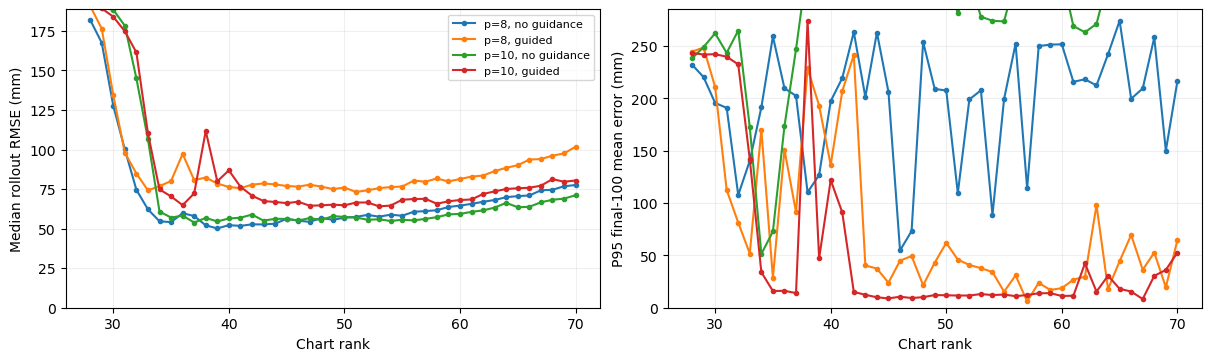

rank,output_dimension,reference_mode,graph_guidance,seeds,successes,success_rate,median_error_mm,p90_error_mm,p95_error_mm,p99_error_mm,median_rollout_rmse_mm,pooled_rmse_mm,unsolved_steps,failed_seeds,median_time_ms,p95_time_ms,p99_time_ms,timing_workers,summary_sha256,source_directory,rank60_reused,inaccurate_steps,K,solver_status_counts,clusters,serial
28,8,terminal,False,100,0,0.0,169.538,225.279,232.306,261.574,182.045,185.291,2,"[211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310]",20.571,43.432,74.111,4,dfdd5466d44969a9e95abd8f163163d76366a47a6e8df15e4f6a54b3e3a234af,/Users/kumiko/Projects/atlas_deepc_reacher/experiments/reacher/large_k_rank_compact_v1/k096/sweep/rank028/output8/terminal,False,NaN,96,"{'optimal': 31998, 'user_limit': 2}",96.0,False
29,8,terminal,False,100,0,0.0,144.453,206.509,220.408,264.351,167.486,168.055,0,"[211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310]",19.761,34.851,61.688,4,fcc7944a16f30b45996a30eebb0fcb70fe2e2eaab3d5562345819347f9272570,/Users/kumiko/Projects/atlas_deepc_reacher/experiments/reacher/large_k_rank_compact_v1/k096/sweep/rank029/output8/terminal,False,NaN,96,{'optimal': 32000},96.0,False
30,8,terminal,False,100,4,4.0,74.027,166.980,195.685,233.469,127.693,136.928,0,"[211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 287, 288, 289, 290, 291, 293, 294, 295, 296, 297, 298, 299, 300, 301, 303, 304, 305, 306, 307, 308, 309, 310]",18.478,27.900,52.776,4,66c7bee3edd02408e27ca849b4a8c163d0e8729aec0d9be3c09e3feb875e7f12,/Users/kumiko/Projects/atlas_deepc_reacher/experiments/reacher/large_k_rank_compact_v1/k096/sweep/rank030/output8/terminal,False,NaN,96,{'optimal': 32000},96.0,False
31,8,terminal,False,100,25,25.0,25.721,129.869,191.015,214.485,100.088,117.139,0,"[211, 212, 213, 214, 215, 216, 217, 218, 219, 222, 223, 224, 226, 227, 228, 229, 231, 232, 234, 236, 238, 239, 240, 241, 242, 244, 245, 246, 247, 248, 251, 252, 253, 254, 255, 256, 257, 260, 262, 263, 264, 265, 266, 267, 268, 270, 272, 273, 274, 275, 277, 278, 280, 282, 283, 284, 285, 287, 288, 290, 291, 294, 295, 296, 298, 299, 301, 303, 304, 305, 306, 307, 308, 309, 310]",18.837,27.419,51.845,4,61bbcf1cb660f6042daa91916eda2be9feff2f1a99a0449b5df6e66b9de2c110,/Users/kumiko/Projects/atlas_deepc_reacher/experiments/reacher/large_k_rank_compact_v1/k096/sweep/rank031/output8/terminal,False,NaN,96,{'optimal': 32000},96.0,False
32,8,terminal,False,100,37,37.0,15.605,77.171,107.739,133.212,74.546,95.015,0,"[212, 214, 215, 216, 217, 221, 223, 224, 227, 229, 230, 231, 234, 236, 237, 238, 239, 240, 241, 242, 243, 245, 246, 247, 248, 251, 252, 253, 254, 255, 256, 257, 259, 260, 263, 265, 267, 268, 269, 270, 273, 274, 275, 277, 278, 280, 282, 283, 287, 290, 291, 293, 298, 299, 300, 301, 303, 305, 306, 307, 308, 309, 310]",18.734,28.078,52.552,4,d

rank  \
output_dimension reference_mode         
8                terminal          57   
                 graph             57   
10               terminal          54   
                 graph             45   

                                                                      failed_seeds  
output_dimension reference_mode                                                     
8                terminal        [222, 236, 245, 252, 276, 287, 290, 292, 296, ...  
                 graph                                   [236, 245, 252, 287, 299]  
10               terminal        [236, 245, 250, 252, 262, 271, 277, 284, 287, ...  
                 graph                                        [231, 236, 245, 277]

\begin{table}[htbp]
    \centering
    \small
    \begin{tabular}{lrrrr}
        \toprule
        Output dimension & \multicolumn{2}{c}{$p=8$} & \multicolumn{2}{c}{$p=10$} \\
        \cmidrule(lr){2-3}\cmidrule(lr){4-5}
        Graph guidance & No & Yes & No & Yes \\
        \midrule
        Selected rank & 57 & 57 & 54 & 45 \\
        Success rate $\uparrow$ & 89\% & 95\% & 85\% & \textbf{96\%} \\
        Median error (mm) $\downarrow$ & \textbf{1.67} & 2.18 & 2.54 & 3.17 \\
        90th-percentile error (mm) $\downarrow$ & 15.535 & \textbf{4.675} & 206.489 & 6.984 \\
        95th-percentile error (mm) $\downarrow$ & 114.062 & \textbf{5.961} & 274.268 & 8.886 \\
        99th-percentile error (mm) $\downarrow$ & 302.095 & \textbf{43.118} & 382.830 & 57.782 \\
        Median rollout RMSE (mm) $\downarrow$ & 61.07 & 79.66 & \textbf{54.83} & 66.13 \\
        \midrule
        \multicolumn{5}{l}{\textit{Total online computation time (ms)}} \\
        Median & 20.49 & 20.33 & 21.61 & 19.43 \

In [10]:
k = 96
data = frame[frame.K == k].copy()
rates = data.pivot(index="rank", columns=["output_dimension", "reference_mode"], values="success_rate")
rates = rates.reindex(columns=pd.MultiIndex.from_tuples(CASES))
rates.columns = LABELS
display(rates.style.format("{:.0f}%"))
best = selected[selected.K == k].set_index(["output_dimension", "reference_mode"]).reindex(CASES)
metrics = ["rank", "success_rate", "median_error_mm", "p90_error_mm", "p95_error_mm", "p99_error_mm",
           "median_rollout_rmse_mm", "median_time_ms", "p95_time_ms", "p99_time_ms"]
table = best[metrics].T
table.columns = LABELS
display(table.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), constrained_layout=True)
for (p, mode), label in zip(CASES, LABELS):
    curve = data[(data.output_dimension == p) & (data.reference_mode == mode)].sort_values("rank")
    for ax, metric, ylabel in ((axes[0], "median_rollout_rmse_mm", "Median rollout RMSE (mm)"),
                               (axes[1], "p95_error_mm", "P95 final-100 mean error (mm)")):
        ax.plot(curve["rank"], curve[metric], ".-", label=label)
        ax.set(xlabel="Chart rank", ylabel=ylabel, ylim=(0, None))
        ax.grid(alpha=.2)
axes[0].legend(fontsize=8)
plt.show()
details = data.drop(columns=["timing_modules", "per_seed_rmse_mm"], errors="ignore")
display(HTML("<details><summary>All saved rank metrics and solver diagnostics</summary>" +
             details.round(3).to_html(index=False) + "</details>"))
if "failed_seeds" in best:
    display(best[["rank", "failed_seeds"]])
latex = SOURCES[k] / "table_best_ranks.tex"
if latex.exists():
    print(latex.read_text())


## Data Provenance
Source folders and hashes are checked when loading. No original results are modified.

In [11]:
display(pd.DataFrame([{"K": k, "source": str(SOURCES[k]),
                           "selection_rule": provenance[k]["selection_rule"]} for k in COUNTS]))


,K,source,selection_rule
0,48,/Users/kumiko/Projects/atlas_deepc/code/experi...,"Highest strict success count, then lowest medi..."
1,64,/Users/kumiko/Projects/atlas_deepc/code/experi...,"Highest strict success count, then lowest medi..."
2,80,/Users/kumiko/Projects/atlas_deepc/code/experi...,"Highest strict success count, then lowest medi..."
3,96,/Users/kumiko/Projects/atlas_deepc/code/experi...,"Highest strict success count, then lowest medi..."


## Optional: Resume One Low-K Batch

This retains the previous batch interface for K=1,2,4,8,16,24,32 and the three
completion methods (p=8 without/with guidance; p=10 without guidance).
All 21 searches are already complete in the current saved results.
It does not rerun the historical p=10 guided study or the large-K rank sweeps.

Only set RUN_BATCH=True deliberately. BATCH_SIZE limits new rollouts per call;
WORKERS controls concurrent rank panels. T_sim=300; seeds 211--310; ranks 28--70.
Completed seeds are resumable, and losing rank checkpoints are deleted only
after the complete search selects a winner. Avoid running alongside timing studies.


In [12]:
from atlas_deepc.ablations import low_k_completion as study
RESULT_ROOT = ROOT / "experiments/reacher/low_k_missing_batches_t300_v3"
BATCH_SIZE = 100
WORKERS = 4
RUN_BATCH = False
assert study.CONTROL_STEPS == 300
if RUN_BATCH:
    batch = study.run_batch(RESULT_ROOT, batch_size=BATCH_SIZE, workers=WORKERS)
    print("New rollouts in this batch:", batch["batch_completed_rollouts"])
else:
    print("Report only; no experiments launched.")
payload = study.report(RESULT_ROOT)
print("Completed low-K rollouts:", payload["completed_rollouts"], "/ 90300")
print("Complete:", payload["complete"])
display(pd.DataFrame(payload["progress"]))
if RUN_BATCH:
    count_points, count_provenance = load_chart_counts(panels)
    count_frame = pd.DataFrame(count_points).rename(columns={"charts": "K"})
    show_count_table(count_frame)


Report only; no experiments launched.
Completed low-K rollouts: 90300 / 90300
Complete: True


,clusters,output_dimension,reference_mode,completed_rollouts,complete,completed_ranks
0,1,8,terminal,4300,True,43
1,1,8,graph,4300,True,43
2,1,10,terminal,4300,True,43
3,2,8,terminal,4300,True,43
4,2,8,graph,4300,True,43
5,2,10,terminal,4300,True,43
6,4,8,terminal,4300,True,43
7,4,8,graph,4300,True,43
8,4,10,terminal,4300,True,43
9,8,8,terminal,4300,True,43
